# ДЗ №1. Классификация пород кошек и собак

В работе сравниваются две предобученные архитектуры, **ResNet50** и **EfficientNetB0**, на датасете [Oxford-IIIT Pet](https://www.robots.ox.ac.uk/~vgg/data/pets/) (37 пород кошек и собак). Обе модели проходят одинаковый путь из четырёх этапов:

1. **Baseline** — backbone заморожен, обучается только новый классификатор.
2. **Итеративная аугментация** — сначала средние преобразования, затем сильные.
3. **Итеративная разморозка** — сначала последний блок, затем вся сеть. У разных слоёв свой learning rate, сверху стоит `ReduceLROnPlateau`.
4. **Псевдолейблинг** — модель размечает неразмеченный пул и дообучается на нём вместе с train.

Validation используется после каждого крупного этапа, test — только в самом конце. Test не участвует ни в обучении, ни в подборе порога уверенности для псевдометок.

> Ноутбук рассчитан на запуск в Colab с GPU (Tesla T4).

## 1. Окружение

Устанавливаю зависимости, фиксирую seed и выбираю устройство. На CPU те же эксперименты идут в разы дольше, поэтому GPU.

Параметры эксперимента:

| Параметр | Значение |
|---|---|
| Размер входа | 224 × 224 |
| Batch size | 32 |
| Эпохи: baseline | 3 |
| Эпохи: каждый уровень аугментации | 2 |
| Эпохи: каждая разморозка | 2 |
| Эпохи: псевдолейблинг | 3 |
| Порог уверенности для псевдометок | 0.90 |

In [ ]:
%pip install -q torch torchvision scikit-learn pandas matplotlib seaborn tqdm

In [ ]:
# Standard library
import random
import time
from typing import Any, Callable, Dict, Iterator, List, Optional, Tuple

# Data and plots
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Models and metrics
import torch
import torch.nn as nn
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split
from torch import Tensor
from torch.optim import Optimizer
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.utils.data import ConcatDataset, DataLoader, Dataset
from torchvision import datasets, models, transforms
from tqdm.auto import tqdm

In [ ]:
SEED = 42
DATA_ROOT = "data"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

IMAGE_SIZE = 224
BATCH_SIZE = 32

# No workers keeps the output clean (no multiprocessing messages).
NUM_WORKERS = 0

BASELINE_EPOCHS = 3
AUGMENT_EPOCHS = 2
UNFREEZE_EPOCHS = 2
PSEUDO_EPOCHS = 3
PSEUDO_THRESHOLD = 0.90

# With a frozen backbone gradients are off, but BatchNorm running statistics
# still update in train mode. That works as a small adaptation to the new data,
# so it is kept by default. Set to True for a strict freeze.
FREEZE_BN_STATS = False

print("Устройство:", DEVICE)
if DEVICE.type == "cuda":
    print("Видеокарта:", torch.cuda.get_device_name(0))
print("Размер входа:", IMAGE_SIZE, "| batch size:", BATCH_SIZE)
print(
    "Эпохи (baseline, аугментация, разморозка, псевдометки):",
    BASELINE_EPOCHS,
    AUGMENT_EPOCHS,
    UNFREEZE_EPOCHS,
    PSEUDO_EPOCHS,
)

Устройство: cuda
Видеокарта: Tesla T4
Размер входа: 224 | batch size: 32
Эпохи (baseline, аугментация, разморозка, псевдометки): 3 2 2 3


In [ ]:
def set_seed(seed: int) -> None:
    """Make the run reproducible."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(SEED)
print("Seed:", SEED)

Seed: 42


## 2. Датасет

Oxford-IIIT Pet содержит фотографии 37 пород кошек и собак. Официально датасет уже разделён на `trainval` и `test`: первый используют для обучения и валидации, второй — для финальной проверки.

Метки классов беру напрямую из датасета. У `OxfordIIITPet` нет публичного свойства с метками, поэтому обращаемся к `_labels` — это особенность именно этого датасета в torchvision.

In [ ]:
trainval_raw = datasets.OxfordIIITPet(
    root=DATA_ROOT,
    split="trainval",
    target_types="category",
    download=True,
)
test_raw = datasets.OxfordIIITPet(
    root=DATA_ROOT,
    split="test",
    target_types="category",
    download=True,
)

all_targets = np.array(trainval_raw._labels)
test_targets = np.array(test_raw._labels)
class_names = trainval_raw.classes
NUM_CLASSES = len(class_names)

print("Изображений в trainval:", len(trainval_raw))
print("Изображений в test:", len(test_raw))
print("Классов:", NUM_CLASSES)

assert NUM_CLASSES == 37

100%|██████████| 792M/792M [00:31<00:00, 25.5MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 9.93MB/s]


Изображений в trainval: 3680
Изображений в test: 3669
Классов: 37


### 2.1. Распределение по классам

Смотрю, нет ли заметного дисбаланса: если один класс встречается в разы чаще другого, метрики вроде accuracy начинают вводить в заблуждение и нужны веса классов.

In [ ]:
class_counts = pd.Series(all_targets).value_counts().sort_index()

class_table = pd.DataFrame({
    "порода": class_names,
    "изображений": class_counts.values,
    "доля, %": (class_counts.values / len(all_targets) * 100).round(2),
})
display(class_table)

print("Минимум в классе:", class_counts.min())
print("Максимум в классе:", class_counts.max())
print("Отношение max/min:", round(class_counts.max()
                                  / class_counts.min(), 2))

plt.figure(figsize=(14, 4))
plt.bar(class_names, class_counts.values)
plt.xticks(rotation=90)
plt.title("Количество изображений на класс (trainval)")
plt.ylabel("Изображений")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

Классы почти сбалансированы: от 93 до 100 изображений, отношение максимума к минимуму — 1.08. Взвешивать классы не нужно, а для разбиения достаточно стратификации.

## 3. Разбиение trainval

`trainval` делю на три непересекающиеся части в пропорции 70/15/15:

- **train** — на нём учимся;
- **validation** — на нём сравниваем этапы и принимаем решения;
- **unlabeled pool** — изображения без меток для псевдолейблинга.

Стратификация сохраняет доли классов во всех частях. Истинные метки пула сохраняю отдельно (`y_unlabeled_hidden`): они нужны только для диагностики качества псевдометок и в обучении не участвуют.

In [ ]:
indices = np.arange(len(trainval_raw))

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=SEED,
    stratify=all_targets,
)
val_idx, unlabeled_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=SEED,
    stratify=all_targets[temp_idx],
)

y_train = all_targets[train_idx]
y_val = all_targets[val_idx]
y_unlabeled_hidden = all_targets[unlabeled_idx]

print("train:", len(train_idx))
print("validation:", len(val_idx))
print("unlabeled pool:", len(unlabeled_idx))
print("test:", len(test_raw))

assert not set(train_idx) & set(val_idx)
assert not set(train_idx) & set(unlabeled_idx)
assert not set(val_idx) & set(unlabeled_idx)

In [ ]:
split_shares = pd.DataFrame({
    "train": pd.Series(y_train).value_counts(normalize=True),
    "validation": pd.Series(y_val).value_counts(normalize=True),
    "unlabeled": pd.Series(y_unlabeled_hidden).value_counts(normalize=True),
    "test": pd.Series(test_targets).value_counts(normalize=True),
}).sort_index() * 100

display(split_shares.round(2))

max_gap = (split_shares.max(axis=1) - split_shares.min(axis=1)).max()
print(f"Максимальное расхождение долей: {max_gap:.2f} п.п.")

plt.figure(figsize=(12, 4))
for column in split_shares.columns:
    plt.plot(
        split_shares.index,
        split_shares[column],
        marker=".",
        label=column,
    )
plt.title("Доли классов в выборках")
plt.xlabel("Номер класса")
plt.ylabel("Доля, %")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

Доли классов во всех четырёх выборках почти совпадают — стратификация сохранила структуру датасета, и validation честно отражает распределение теста. Пересечений между частями нет: это проверено в коде выше.

## 4. Аугментации

Перед подачей в сеть изображения приводятся к 224 × 224 и нормализуются по статистикам ImageNet. Так модели получают данные в том же виде, в котором учились на ImageNet.

Использую три уровня аугментации:

- **weak** — горизонтальное отражение;
- **medium** — отражение, небольшой поворот и лёгкое изменение цвета;
- **strong** — случайный кроп с масштабированием, более сильные поворот и цвет.

Идея итеративной аугментации: не включать сразу сильные искажения, а усложнять их постепенно. Сначала модель осваивается на простых вариантах, потом учится быть устойчивой к более широкому диапазону условий.

In [ ]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)


def make_transform(level: str) -> transforms.Compose:
    """Build the image pipeline for the given augmentation level."""
    if level == "eval":
        operations = [transforms.Resize((IMAGE_SIZE, IMAGE_SIZE))]
    elif level == "weak":
        operations = [
            transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
            transforms.RandomHorizontalFlip(p=0.5),
        ]
    elif level == "medium":
        operations = [
            transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomRotation(12),
            transforms.ColorJitter(
                brightness=0.15,
                contrast=0.15,
                saturation=0.15,
                hue=0.03,
            ),
        ]
    elif level == "strong":
        operations = [
            transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.75, 1.0)),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomRotation(20),
            transforms.ColorJitter(
                brightness=0.25,
                contrast=0.25,
                saturation=0.25,
                hue=0.05,
            ),
        ]
    else:
        raise ValueError(f"Неизвестный уровень аугментации: {level}")

    operations.extend([
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ])
    return transforms.Compose(operations)


def denormalize(image_tensor: Tensor) -> np.ndarray:
    """Turn a normalized CHW tensor back into an RGB array for plotting."""
    image = image_tensor.permute(1, 2, 0).numpy()
    image = image * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)
    return np.clip(image, 0, 1)

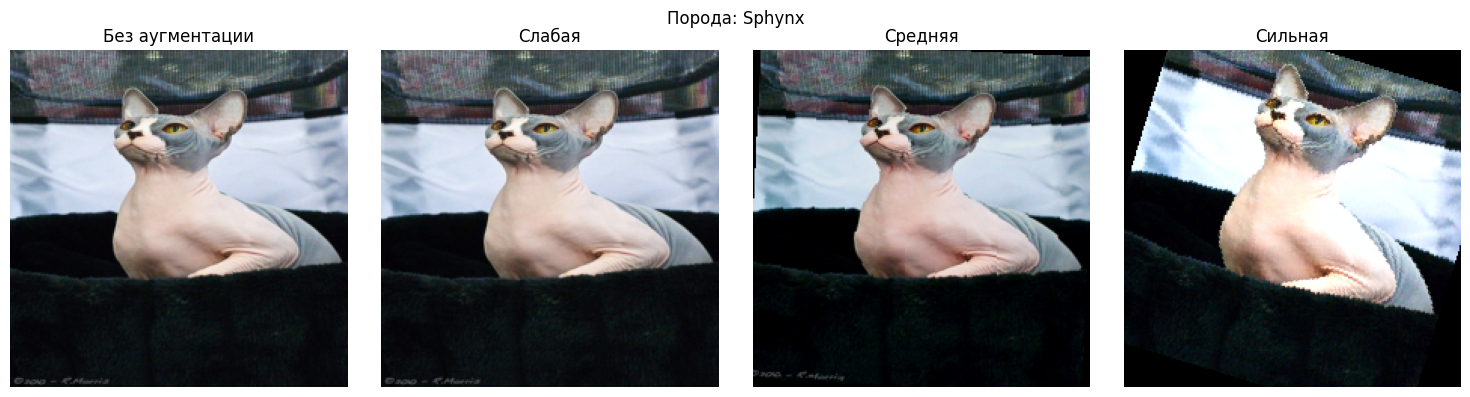

In [ ]:
def show_augmentations(dataset: Dataset, index: int = 0) -> None:
    """Show the same image under every augmentation level."""
    image, label = dataset[index]
    levels = ["eval", "weak", "medium", "strong"]
    titles = ["Без аугментации", "Слабая", "Средняя", "Сильная"]

    fig, axes = plt.subplots(1, len(levels), figsize=(15, 4))
    for ax, level, title in zip(axes, levels, titles):
        augmented = make_transform(level)(image)
        ax.imshow(denormalize(augmented))
        ax.set_title(title)
        ax.axis("off")

    fig.suptitle(f"Порода: {dataset.classes[label]}")
    plt.tight_layout()
    plt.show()


show_augmentations(trainval_raw, index=train_idx[0])

На сильном уровне объект может заметно обрезаться и сдвинуться, но голова, окрас и форма тела остаются различимыми. Именно эти признаки и нужны, чтобы отличить одну породу от другой.

## 5. Обёртка датасета

`PetSubset` позволяет взять подмножество исходного датасета по индексам, применить к нему нужное преобразование и при необходимости подменить метки. Последнее пригодится для псевдолейблинга.

In [ ]:
class PetSubset(Dataset):
    """Dataset subset with its own transform and optional new labels."""

    def __init__(
        self,
        base_dataset: Dataset,
        indices: np.ndarray,
        transform: Callable[[Any], Tensor],
        labels: Optional[np.ndarray] = None,
    ) -> None:
        self.base_dataset: Dataset = base_dataset
        self.indices: np.ndarray = np.asarray(indices)
        self.transform: Callable[[Any], Tensor] = transform
        self.labels: Optional[np.ndarray] = (
            None if labels is None else np.asarray(labels)
        )

    def __len__(self) -> int:
        return len(self.indices)

    def __getitem__(self, index: int) -> Tuple[Tensor, int]:
        image, label = self.base_dataset[int(self.indices[index])]
        if self.labels is not None:
            label = self.labels[index]
        return self.transform(image), int(label)


def make_loader(dataset: Dataset, shuffle: bool = False) -> DataLoader:
    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=NUM_WORKERS,
        pin_memory=DEVICE.type == "cuda",
    )


val_dataset = PetSubset(trainval_raw, val_idx, make_transform("eval"))
test_dataset = PetSubset(
    test_raw,
    np.arange(len(test_raw)),
    make_transform("eval"),
)

val_loader = make_loader(val_dataset)
test_loader = make_loader(test_dataset)

print("Батчей в validation:", len(val_loader))
print("Батчей в test:", len(test_loader))

Батчей в validation: 18
Батчей в test: 115


## 6. Модели

ResNet50 использует остаточные связи: они упрощают обучение глубокой сети и позволяют сохранять информацию между слоями. EfficientNetB0 построен на сбалансированном масштабировании глубины, ширины и разрешения — при меньшем числе параметров он конкурентоспособен по качеству.

Обе модели беру с весами ImageNet и заменяю последний слой на новый классификатор для 37 пород. В начале backbone заморожен: обучается только голова. Затем последний блок размораживается, а после него — вся сеть.

Ориентир по качеству: на Oxford-IIIT Pet предобученные CNN обычно дают 90–95% accuracy, поэтому планка для сравнения этапов — выйти к верхней части этого диапазона. Важно увидеть, какой приём и насколько помогает каждой архитектуре.


In [ ]:
def create_model(model_name: str) -> nn.Module:
    """Pretrained backbone with a fresh classifier for 37 breeds."""
    if model_name == "ResNet50":
        model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
    elif model_name == "EfficientNetB0":
        model = models.efficientnet_b0(
            weights=models.EfficientNet_B0_Weights.DEFAULT,
        )
        model.classifier[1] = nn.Linear(
            model.classifier[1].in_features,
            NUM_CLASSES,
        )
    else:
        raise ValueError(f"Неизвестная архитектура: {model_name}")

    return model.to(DEVICE)


def classifier_parameters(
    model: nn.Module,
    model_name: str,
) -> Iterator[nn.Parameter]:
    """Parameters of the head, the only trainable part at the start."""
    if model_name == "ResNet50":
        return model.fc.parameters()
    return model.classifier[1].parameters()


def freeze_backbone(model: nn.Module, model_name: str) -> None:
    for parameter in model.parameters():
        parameter.requires_grad = False
    for parameter in classifier_parameters(model, model_name):
        parameter.requires_grad = True


def unfreeze_last_block(model: nn.Module, model_name: str) -> None:
    if model_name == "ResNet50":
        last_block = model.layer4
    else:
        last_block = model.features[-2:]
    for parameter in last_block.parameters():
        parameter.requires_grad = True


def unfreeze_all(model: nn.Module) -> None:
    for parameter in model.parameters():
        parameter.requires_grad = True

## 7. Метрики

Считаю accuracy, macro-precision, macro-recall и macro-F1. Основная метрика — **macro-F1**: она усредняет F1 по классам без учёта их размера, поэтому не даёт «спрятать» плохое качество на отдельной породе за средним. Loss тоже сохраняю: по нему видно, когда модель начинает переобучаться.

In [ ]:
def evaluate(
    model: nn.Module,
    data_loader: DataLoader,
) -> Tuple[Dict[str, float], np.ndarray, np.ndarray]:
    model.eval()
    criterion = nn.CrossEntropyLoss()

    all_true: List[int] = []
    all_pred: List[int] = []
    total_loss = 0.0

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            logits = model(images)
            total_loss += criterion(logits, labels).item() * len(labels)

            predictions = logits.argmax(dim=1)
            all_true.extend(labels.cpu().numpy())
            all_pred.extend(predictions.cpu().numpy())

    precision, recall, f1, _ = precision_recall_fscore_support(
        all_true,
        all_pred,
        average="macro",
        zero_division=0,
    )
    metrics = {
        "loss": total_loss / len(all_true),
        "accuracy": accuracy_score(all_true, all_pred),
        "precision_macro": precision,
        "recall_macro": recall,
        "f1_macro": f1,
    }

    return metrics, np.array(all_true), np.array(all_pred)

## 8. Обучение

Для baseline и этапов аугментации учится только голова: `AdamW` с lr 1e-3 и 3e-4 соответственно.

На разморозке появляется несколько групп параметров. Ранние слои меняются слабее (lr 1e-5), последний блок — сильнее (1e-4), голова — сильнее всех (5e-4). Так предобученные признаки не разрушаются большими шагами.

Отдельно про заморозку. Backbone отключён по градиентам (`requires_grad=False`), поэтому веса предобученных слоёв не меняются. Но вызов `model.train()` переводит в режим обучения и BatchNorm: у этих слоёв обновляются running-статистики, хотя параметры остаются на месте. Это осознанный компромисс — статистики немного подстраиваются под новый датасет, и замороженные признаки работают на нём чуть иначе. Если нужна строгая заморозка, в настройках есть флаг `FREEZE_BN_STATS`: при `True` слои BatchNorm с выключенными градиентами остаются в `eval()`.

`ReduceLROnPlateau` следит за validation loss и делит lr на 2, если он перестал уменьшаться (`patience=0`). В коротких этапах scheduler срабатывает не всегда, поэтому в историю пишутся lr самой медленной и самой быстрой групп — по ним видно и дифференцированный lr при разморозке, и работу scheduler.


In [ ]:
def set_train_mode(model: nn.Module) -> None:
    """Switch to train mode; keep frozen BatchNorm layers in eval if asked."""
    model.train()
    if not FREEZE_BN_STATS:
        return
    for module in model.modules():
        if isinstance(module, nn.BatchNorm2d):
            if not module.weight.requires_grad:
                module.eval()


def learning_rates(optimizer: Optimizer) -> Tuple[float, float]:
    """Smallest and largest learning rate among the parameter groups."""
    rates = [group["lr"] for group in optimizer.param_groups]
    return min(rates), max(rates)


def train_one_stage(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    epochs: int,
    optimizer: Optimizer,
    scheduler: ReduceLROnPlateau,
    stage_name: str,
) -> pd.DataFrame:
    criterion = nn.CrossEntropyLoss()
    history: List[Dict[str, Any]] = []

    for epoch in range(1, epochs + 1):
        set_train_mode(model)
        running_loss = 0.0
        correct = 0
        total = 0

        progress = tqdm(
            train_loader,
            desc=f"{stage_name}, эпоха {epoch}/{epochs}",
            leave=False,
        )
        for images, labels in progress:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * len(labels)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += len(labels)
            progress.set_postfix(
                loss=round(running_loss / total, 4),
                accuracy=round(correct / total, 4),
            )

        train_loss = running_loss / total
        train_accuracy = correct / total
        val_metrics, _, _ = evaluate(model, val_loader)

        # Read the rates before stepping, so the row shows the rates used.
        lr_backbone, lr_head = learning_rates(optimizer)
        scheduler.step(val_metrics["loss"])

        history.append({
            "stage": stage_name,
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "lr_backbone": lr_backbone,
            "lr_head": lr_head,
        })
        print(
            f"{stage_name} | эпоха {epoch}: "
            f"train acc {train_accuracy:.4f}, "
            f"val acc {val_metrics['accuracy']:.4f}, "
            f"val loss {val_metrics['loss']:.4f}, "
            f"lr {lr_backbone:.1e}...{lr_head:.1e}"
        )

    return pd.DataFrame(history)


def record_stage(
    stage_results: List[Dict[str, Any]],
    model_name: str,
    stage_name: str,
    model: nn.Module,
    data_loader: DataLoader,
) -> None:
    """Evaluate the model and add one row to the stage summary."""
    metrics, _, _ = evaluate(model, data_loader)
    stage_results.append({
        "model": model_name,
        "stage": stage_name,
        **metrics,
    })


def make_head_optimizer(
    model: nn.Module,
    model_name: str,
    lr: float = 1e-3,
) -> Optimizer:
    return torch.optim.AdamW(
        classifier_parameters(model, model_name),
        lr=lr,
        weight_decay=1e-4,
    )


def make_fine_tuning_optimizer(
    model: nn.Module,
    model_name: str,
) -> Optimizer:
    if model_name == "ResNet50":
        parameter_groups = [
            {"params": list(model.conv1.parameters()), "lr": 1e-5},
            {"params": list(model.bn1.parameters()), "lr": 1e-5},
            {"params": list(model.layer1.parameters()), "lr": 1e-5},
            {"params": list(model.layer2.parameters()), "lr": 2e-5},
            {"params": list(model.layer3.parameters()), "lr": 5e-5},
            {"params": list(model.layer4.parameters()), "lr": 1e-4},
            {"params": list(model.fc.parameters()), "lr": 5e-4},
        ]
    else:
        parameter_groups = [
            {"params": list(model.features.parameters()), "lr": 2e-5},
            {"params": list(model.classifier.parameters()), "lr": 5e-4},
        ]

    # Only unfrozen parameters go into the optimizer.
    trainable_groups = []
    for group in parameter_groups:
        trainable = [
            parameter for parameter in group["params"]
            if parameter.requires_grad
        ]
        if trainable:
            trainable_groups.append({
                "params": trainable,
                "lr": group["lr"],
            })

    return torch.optim.AdamW(trainable_groups, weight_decay=1e-4)


def make_scheduler(optimizer: Optimizer) -> ReduceLROnPlateau:
    # patience=0 reacts to the first epoch without improvement. The stages
    # here last two or three epochs, so a larger patience would never trigger.
    return ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=0,
    )

## 9. Псевдолейблинг

Модель прогоняет неразмеченный пул (552 изображения) и оставляет предсказания, в которых уверена не меньше чем на 0.90. Эти изображения вместе с их псевдометками добавляются к train, и сеть дообучается ещё несколько эпох.

Порог 0.90 — компромисс: ниже него в обучение попадёт больше примеров, но и больше ошибок; выше — псевдометки чище, но их может оказаться слишком мало. Истинные метки пула при генерации не используются.

In [ ]:
def generate_pseudo_labels(
    model: nn.Module,
) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    dataset = PetSubset(
        trainval_raw,
        unlabeled_idx,
        make_transform("eval"),
    )
    loader = make_loader(dataset)

    model.eval()
    selected_indices = []
    selected_labels = []
    selected_confidences = []
    offset = 0

    progress = tqdm(loader, desc="Генерация псевдометок", leave=False)
    with torch.no_grad():
        for images, _ in progress:
            logits = model(images.to(DEVICE))
            probabilities = torch.softmax(logits, dim=1)
            confidence, prediction = probabilities.max(dim=1)

            confidence = confidence.cpu().numpy()
            prediction = prediction.cpu().numpy()

            batch_indices = unlabeled_idx[offset:offset + len(confidence)]
            mask = confidence >= PSEUDO_THRESHOLD

            selected_indices.append(batch_indices[mask])
            selected_labels.append(prediction[mask])
            selected_confidences.append(confidence[mask])
            offset += len(confidence)

    return (
        np.concatenate(selected_indices),
        np.concatenate(selected_labels),
        np.concatenate(selected_confidences),
    )

## 10. Полный эксперимент

`run_experiment` проводит одну архитектуру через все этапы и возвращает обученную модель, историю, сводку по этапам и псевдометки.

Порядок этапов:

1. **Baseline** — 3 эпохи со слабой аугментацией.
2. **Аугментация** — 2 эпохи с medium и 2 эпохи со strong. Backbone всё ещё заморожен.
3. **Разморозка** — 2 эпохи с размороженным последним блоком и 2 эпохи с полностью размороженной сетью. На каждом шаге создаётся новый оптимизатор с lr, подобранными под группы слоёв.
4. **Псевдометки** — генерация меток для пула и 3 эпохи на объединении train и размеченного пула.

Обе архитектуры видят одни и те же данные и одни и те же параметры. Разница только в структуре сети.

In [ ]:
def run_experiment(model_name: str) -> Dict[str, Any]:
    print("=" * 60)
    print("Модель:", model_name)
    print("=" * 60)

    started_at = time.time()
    model = create_model(model_name)
    freeze_backbone(model, model_name)

    histories = []
    stage_results = []

    # 1. Baseline: only the head is trained.
    baseline_loader = make_loader(
        PetSubset(trainval_raw, train_idx, make_transform("weak")),
        shuffle=True,
    )
    optimizer = make_head_optimizer(model, model_name, lr=1e-3)
    scheduler = make_scheduler(optimizer)

    histories.append(train_one_stage(
        model,
        baseline_loader,
        val_loader,
        BASELINE_EPOCHS,
        optimizer,
        scheduler,
        "Базовая",
    ))
    record_stage(stage_results, model_name, "Базовая", model, val_loader)

    # 2. Iterative augmentation: medium, then strong.
    for level, stage_name in [
        ("medium", "Аугментация: medium"),
        ("strong", "Аугментация: strong"),
    ]:
        loader = make_loader(
            PetSubset(trainval_raw, train_idx, make_transform(level)),
            shuffle=True,
        )
        optimizer = make_head_optimizer(model, model_name, lr=3e-4)
        scheduler = make_scheduler(optimizer)

        histories.append(train_one_stage(
            model,
            loader,
            val_loader,
            AUGMENT_EPOCHS,
            optimizer,
            scheduler,
            stage_name,
        ))

    record_stage(stage_results, model_name, "Аугментация", model, val_loader)

    # 3. Iterative unfreezing: the last block, then the whole network.
    strong_loader = make_loader(
        PetSubset(trainval_raw, train_idx, make_transform("strong")),
        shuffle=True,
    )

    unfreeze_last_block(model, model_name)
    optimizer = make_fine_tuning_optimizer(model, model_name)
    scheduler = make_scheduler(optimizer)

    histories.append(train_one_stage(
        model,
        strong_loader,
        val_loader,
        UNFREEZE_EPOCHS,
        optimizer,
        scheduler,
        "Разморозка: последний блок",
    ))

    unfreeze_all(model)
    optimizer = make_fine_tuning_optimizer(model, model_name)
    scheduler = make_scheduler(optimizer)

    histories.append(train_one_stage(
        model,
        strong_loader,
        val_loader,
        UNFREEZE_EPOCHS,
        optimizer,
        scheduler,
        "Разморозка: вся сеть",
    ))

    record_stage(
        stage_results,
        model_name,
        "Разморозка + адаптивный lr",
        model,
        val_loader,
    )

    # 4. Pseudo-labelling.
    pseudo_indices, pseudo_labels, pseudo_confidences = (
        generate_pseudo_labels(model)
    )
    print(f"Псевдометок: {len(pseudo_indices)} из {len(unlabeled_idx)}")
    if len(pseudo_confidences) > 0:
        print(f"Средняя уверенность: {pseudo_confidences.mean():.4f}")

    if len(pseudo_indices) > 0:
        labeled_dataset = PetSubset(
            trainval_raw,
            train_idx,
            make_transform("strong"),
        )
        pseudo_dataset = PetSubset(
            trainval_raw,
            pseudo_indices,
            make_transform("strong"),
            labels=pseudo_labels,
        )
        combined_loader = make_loader(
            ConcatDataset([labeled_dataset, pseudo_dataset]),
            shuffle=True,
        )
        optimizer = make_fine_tuning_optimizer(model, model_name)
        scheduler = make_scheduler(optimizer)

        histories.append(train_one_stage(
            model,
            combined_loader,
            val_loader,
            PSEUDO_EPOCHS,
            optimizer,
            scheduler,
            "Псевдометки",
        ))
    else:
        print("Ни один объект не прошёл порог, этап пропущен.")

    record_stage(
        stage_results,
        model_name,
        "После псевдометок",
        model,
        val_loader,
    )

    elapsed = time.time() - started_at
    print(f"Время выполнения: {elapsed / 60:.1f} мин")

    return {
        "model": model,
        "history": pd.concat(histories, ignore_index=True),
        "stages": pd.DataFrame(stage_results),
        "pseudo_indices": pseudo_indices,
        "pseudo_labels": pseudo_labels,
        "pseudo_confidences": pseudo_confidences,
    }

In [ ]:
experiments = {}
for model_name in ["ResNet50", "EfficientNetB0"]:
    experiments[model_name] = run_experiment(model_name)

Модель: ResNet50
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 115MB/s]


Базовая, эпоха 1/3:   0%|          | 0/81 [00:00<?, ?it/s]

Базовая | эпоха 1: train acc 0.6134, val acc 0.8822, val loss 1.2188, lr 1.0e-03...1.0e-03


Базовая, эпоха 2/3:   0%|          | 0/81 [00:00<?, ?it/s]

Базовая | эпоха 2: train acc 0.9278, val acc 0.8877, val loss 0.6896, lr 1.0e-03...1.0e-03


... (53 outputs left out)

Псевдометки, эпоха 2/3:   0%|          | 0/89 [00:00<?, ?it/s]

Псевдометки | эпоха 2: train acc 0.9449, val acc 0.8967, val loss 0.3535, lr 2.0e-05...5.0e-04


Псевдометки, эпоха 3/3:   0%|          | 0/89 [00:00<?, ?it/s]

Псевдометки | эпоха 3: train acc 0.9446, val acc 0.8986, val loss 0.3401, lr 2.0e-05...5.0e-04
Время выполнения: 9.0 мин


## 11. Результаты на validation

Свожу метрики после каждого крупного этапа. На графике — accuracy и macro-F1; остальные метрики есть в таблице.

,model,stage,loss,accuracy,precision_macro,recall_macro,f1_macro
0,ResNet50,Базовая,0.4993,0.8986,0.9059,0.8988,0.8979
1,ResNet50,Аугментация,0.3611,0.9130,0.9205,0.9133,0.9106
2,ResNet50,Разморозка + адаптивный lr,0.2638,0.9149,0.9283,0.9149,0.9148
3,ResNet50,После псевдометок,0.2295,0.9348,0.9416,0.9347,0.9343
4,EfficientNetB0,Базовая,0.6831,0.8406,0.8502,0.8413,0.8386
5,EfficientNetB0,Аугментация,0.7436,0.8134,0.8244,0.8136,0.8131
6,EfficientNetB0,Разморозка + адаптивный lr,0.4242,0.8768,0.8844,0.8773,0.8762
7,EfficientNetB0,После псевдометок,0.3401,0.8986,0.9059,0.8990,0.8989


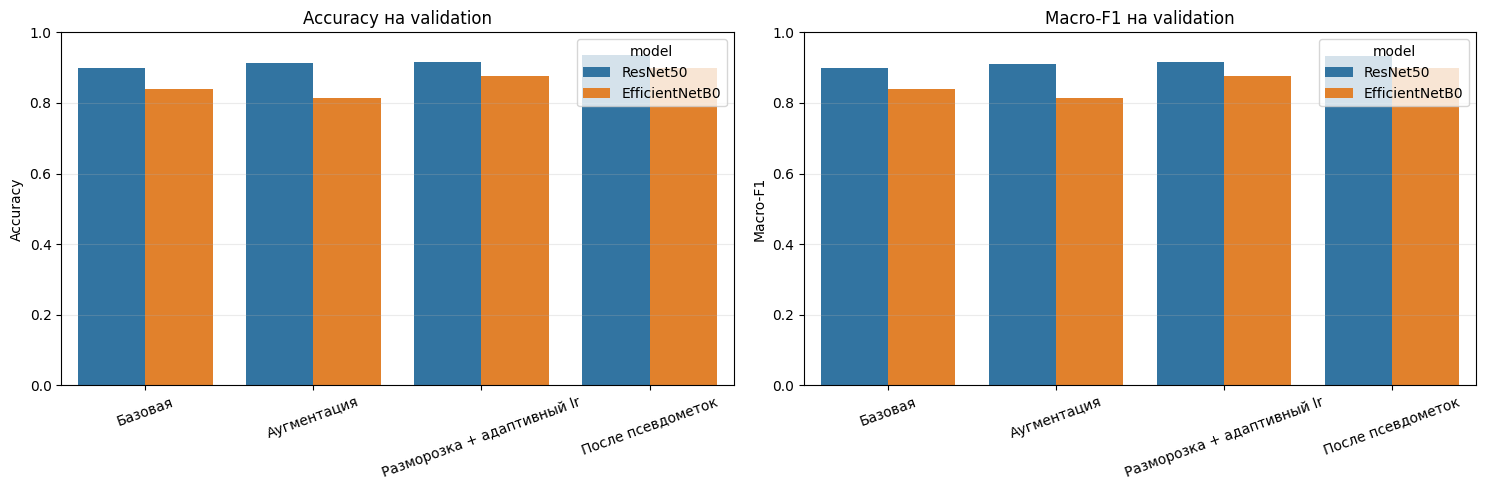

In [23]:
validation_results = pd.concat(
    [result["stages"] for result in experiments.values()],
    ignore_index=True,
)
display(validation_results.round(4))

stage_order = validation_results["stage"].drop_duplicates().tolist()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, metric, title in zip(
    axes,
    ["accuracy", "f1_macro"],
    ["Accuracy", "Macro-F1"],
):
    sns.barplot(
        data=validation_results,
        x="stage",
        y=metric,
        hue="model",
        order=stage_order,
        ax=ax,
    )
    ax.set_title(f"{title} на validation")
    ax.set_xlabel("")
    ax.set_ylabel(title)
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

Перевожу таблицу в пары чисел (accuracy на validation):

- **ResNet50**: 89,86% → 91,30% → 91,49% → 93,48%;
- **EfficientNetB0**: 84,06% → 81,34% → 87,68% → 89,86%.

Поведение архитектур получилось разным, и это главный результат раздела.

У **ResNet50** каждый этап добавляет понемногу: аугментация +1.44 п.п., разморозка +0,19 п.п., псевдометки +1,99 п.п. Прирост небольшой, но он есть на каждом этапе — откатов нет.

У **EfficientNetB0** аугментация при замороженном backbone даёт −2,72 п.п.: сильные искажения уводят картинки из распределения ImageNet, а голове нечем это компенсировать. Зато разморозка возвращает +6,34 п.п., и псевдометки добавляют ещё +2,18 п.п. — итог 89,86% против 84,06% на baseline.

Значит, эффект одного и того же приёма зависит от архитектуры и от того, на каком этапе он применяется. На более сильной модели аугментация работает скорее как регуляризация, на слабой без разморозки — скорее мешает.

Числа немного различаются между запусками из-за недетерминированности CUDA, но порядок этапов и общая картина сохраняются.


## 12. Качество псевдометок

Отдельно проверяю, что именно модель разметила в пуле. Здесь впервые используются скрытые метки пула, и только как диагностика: на обучение они не влияли.

In [24]:
true_labels_by_index = dict(zip(unlabeled_idx, y_unlabeled_hidden))

diagnostics = []
for model_name, result in experiments.items():
    indices = result["pseudo_indices"]

    if len(indices) > 0:
        true_labels = np.array([
            true_labels_by_index[int(index)]
            for index in indices
        ])
        pseudo_accuracy = accuracy_score(
            true_labels,
            result["pseudo_labels"],
        )
        mean_confidence = result["pseudo_confidences"].mean()
    else:
        pseudo_accuracy = np.nan
        mean_confidence = np.nan

    diagnostics.append({
        "model": model_name,
        "объектов в пуле": len(unlabeled_idx),
        "псевдометок": len(indices),
        "доля пула, %": len(indices) / len(unlabeled_idx) * 100,
        "средняя уверенность": mean_confidence,
        "точность псевдометок": pseudo_accuracy,
    })

pseudo_diagnostics = pd.DataFrame(diagnostics)
display(pseudo_diagnostics.round(4))

,model,объектов в пуле,псевдометок,"доля пула, %",средняя уверенность,точность псевдометок
0,ResNet50,552,465,84.2391,0.9885,0.9785
1,EfficientNetB0,552,257,46.5580,0.9665,0.9922


Разница в количестве объясняется тем, что вероятности EfficientNetB0 в среднем ниже: при том же пороге 0.90 под него попадает меньше объектов. Зато отобранные метки у неё почти безошибочны.

Это компромисс «количество против чистоты». При более низком пороге обе модели взяли бы больше данных, но с большей долей ошибок; при более высоком — меньше, но надёжнее. У ResNet50 ошибок около 10 изображений из 465, поэтому на итоговое качество они почти не влияют.

## 13. Итоговые результаты на test

Test не использовался ни на одном этапе. Сравниваю финальные модели по тем же метрикам.

,model,loss,accuracy,precision_macro,recall_macro,f1_macro
0,ResNet50,0.3487,0.9052,0.9082,0.9045,0.9023
1,EfficientNetB0,0.4578,0.8585,0.8623,0.8578,0.8561


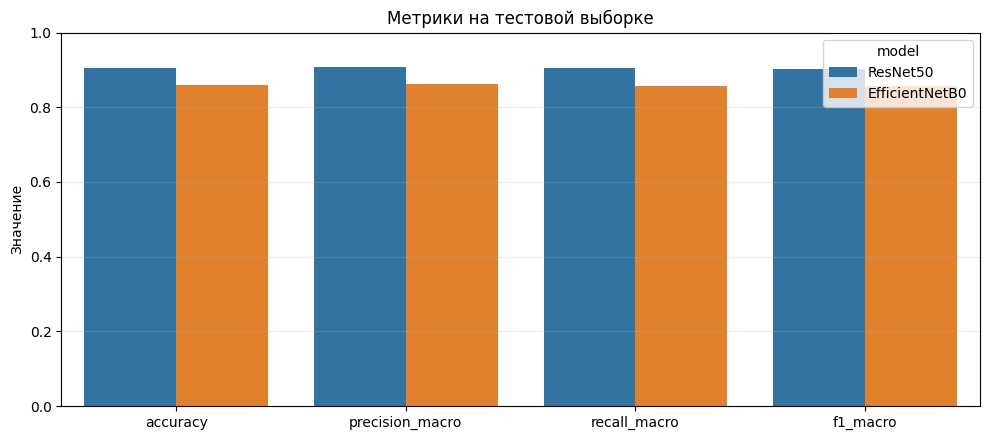

Лучшая модель по macro-F1: ResNet50


In [25]:
test_results = []
test_predictions = {}

for model_name, result in experiments.items():
    metrics, y_true, y_pred = evaluate(result["model"], test_loader)
    test_results.append({"model": model_name, **metrics})
    test_predictions[model_name] = (y_true, y_pred)

test_results = pd.DataFrame(test_results)
display(test_results.round(4))

plot_data = test_results.melt(
    id_vars="model",
    value_vars=["accuracy", "precision_macro", "recall_macro", "f1_macro"],
    var_name="метрика",
    value_name="значение",
)

plt.figure(figsize=(10, 4.5))
sns.barplot(data=plot_data, x="метрика", y="значение", hue="model")
plt.ylim(0, 1)
plt.title("Метрики на тестовой выборке")
plt.xlabel("")
plt.ylabel("Значение")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

best = test_results.loc[test_results["f1_macro"].idxmax()]
print("Лучшая модель по macro-F1:", best["model"])

На test разрыв сохраняется: ResNet50 — accuracy 90,52% и macro-F1 90,23%, EfficientNetB0 — 85,85% и 85,61%.

Значит, выводы с validation не были случайностью: полный цикл из аугментации, разморозки и псевдометок доводит более сильную архитектуру до более высокого результата. Обе модели на test немного ниже, чем на validation, — это ожидаемо: тестовая выборка не участвовала ни в обучении, ни в выборе решений.

## 14. Какие породы даются сложнее

Смотрю на метрики по классам и на матрицу ошибок. Матрицу нормирую по строкам: так видно, в какие классы «утекает» каждое истинное значение, независимо от размера класса.

Худшие 5 пород по F1 — ResNet50


,порода,precision,recall,f1,support
2,American Pit Bull Terrier,0.760,0.380,0.507,100
34,Staffordshire Bull Terrier,0.724,0.618,0.667,89
26,Ragdoll,0.861,0.680,0.760,100
1,American Bulldog,0.655,0.930,0.769,100
6,Birman,0.715,0.880,0.789,100


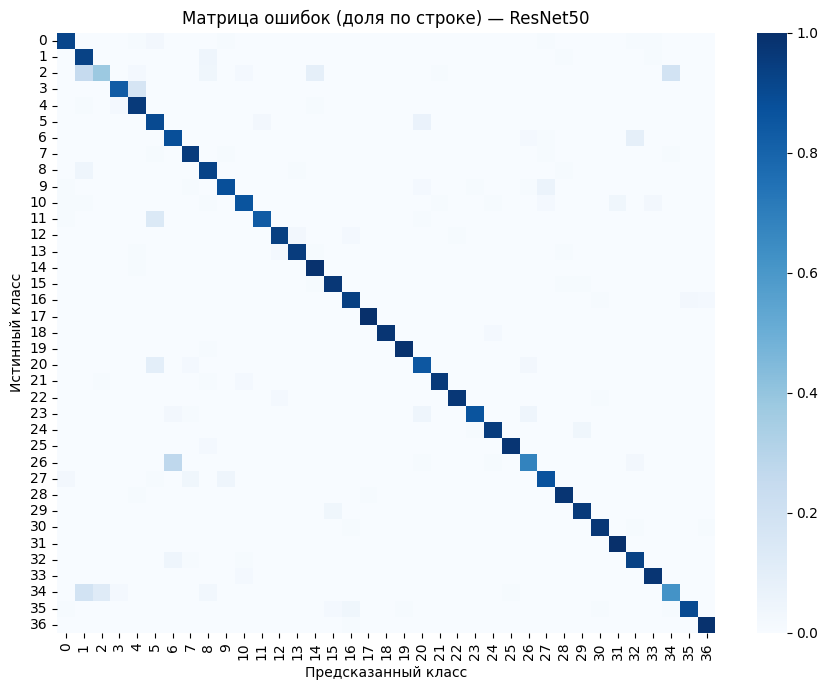

Худшие 5 пород по F1 — EfficientNetB0


,порода,precision,recall,f1,support
34,Staffordshire Bull Terrier,0.622,0.517,0.564,89
2,American Pit Bull Terrier,0.776,0.450,0.570,100
1,American Bulldog,0.618,0.840,0.712,100
26,Ragdoll,0.776,0.660,0.714,100
9,British Shorthair,0.882,0.670,0.761,100


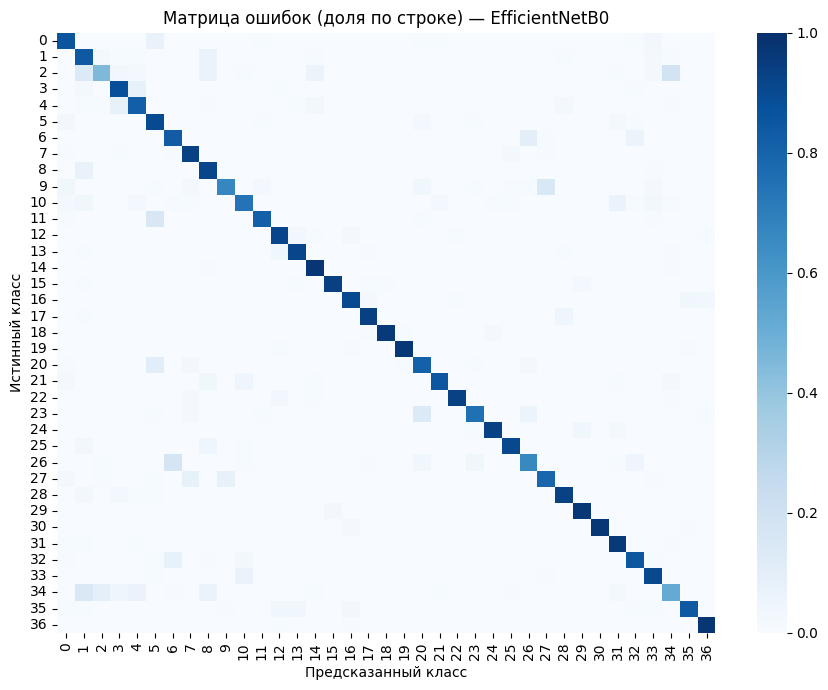

In [26]:
def per_class_metrics(
    y_true: np.ndarray,
    y_pred: np.ndarray,
) -> pd.DataFrame:
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=np.arange(NUM_CLASSES),
        zero_division=0,
    )
    return pd.DataFrame({
        "порода": class_names,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "support": support,
    })


for model_name, (y_true, y_pred) in test_predictions.items():
    table = per_class_metrics(y_true, y_pred)

    print(f"Худшие 5 пород по F1 — {model_name}")
    display(table.sort_values("f1").head(5).round(3))

    matrix = confusion_matrix(
        y_true,
        y_pred,
        labels=np.arange(NUM_CLASSES),
    )
    matrix = matrix / matrix.sum(axis=1, keepdims=True)

    plt.figure(figsize=(9, 7))
    sns.heatmap(matrix, cmap="Blues", vmin=0, vmax=1)
    plt.title(f"Матрица ошибок (доля по строке) — {model_name}")
    plt.xlabel("Предсказанный класс")
    plt.ylabel("Истинный класс")
    plt.tight_layout()
    plt.show()

Обеим моделям тяжелее всего даются визуально близкие породы. В худшую пятёрку, как правило, попадают породы с похожим окрасом, формой морды и телосложением. Ошибки в матрице концентрируются не случайно, а в парах похожих классов: модель путает близкие породы между собой, а не совершенно далёкие. Это ожидаемое поведение для классификатора, который смотрит на форму и цвет, а не на «породу» в кинологическом смысле.

Из-за этого средний macro-F1 ниже обычной accuracy: несколько трудных классов тянут среднее вниз, тогда как большинство остальных распознаётся заметно лучше среднего.

## 15. Динамика обучения

Графики по эпохам помогают понять, где модель переобучается и как на неё влияет смена этапа. На третьей панели — learning rate: видно, что при разморозке у backbone и головы разные значения, а scheduler снижает их, когда validation loss перестаёт падать. Пунктирные линии — границы этапов.

Важная оговорка: train-метрики между этапами сравнивать напрямую нельзя, потому что меняется аугментация. На сильных преобразованиях train accuracy может выглядеть ниже при том же качестве модели — это не деградация, а более сложная задача.


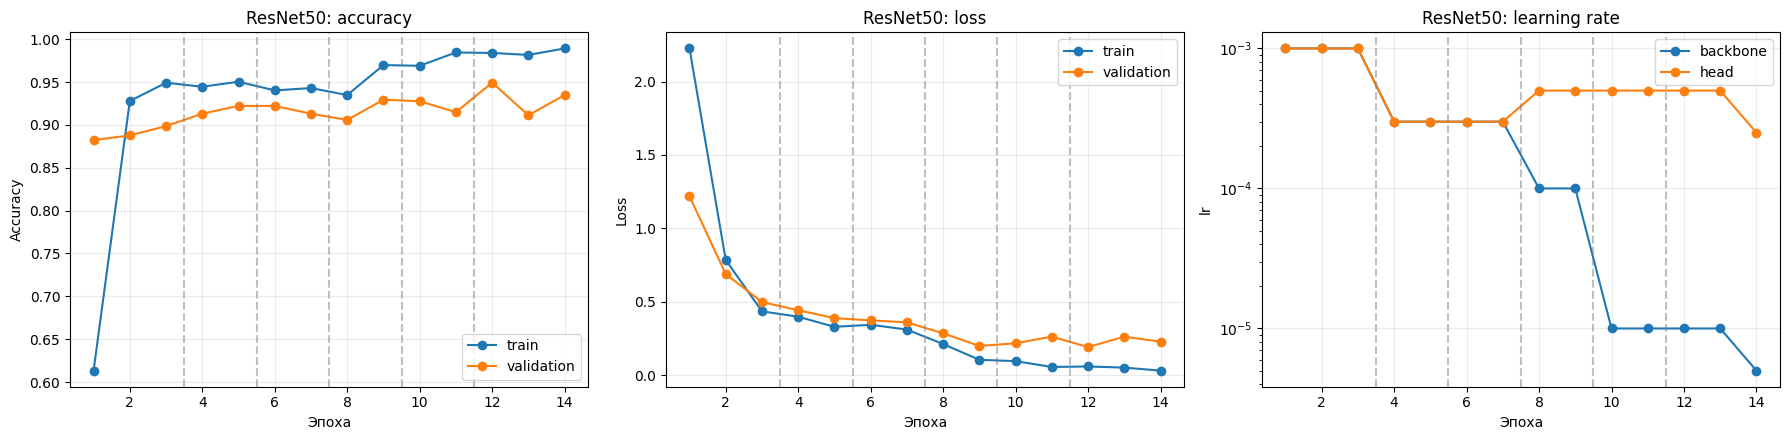


Learning rate по этапам — ResNet50


,backbone_first,backbone_last,head_first,head_last
stage,,,,
Базовая,0.00100,0.001000,0.0010,0.00100
Аугментация: medium,0.00030,0.000300,0.0003,0.00030
Аугментация: strong,0.00030,0.000300,0.0003,0.00030
Разморозка: последний блок,0.00010,0.000100,0.0005,0.00050
Разморозка: вся сеть,0.00001,0.000010,0.0005,0.00050
Псевдометки,0.00001,0.000005,0.0005,0.00025


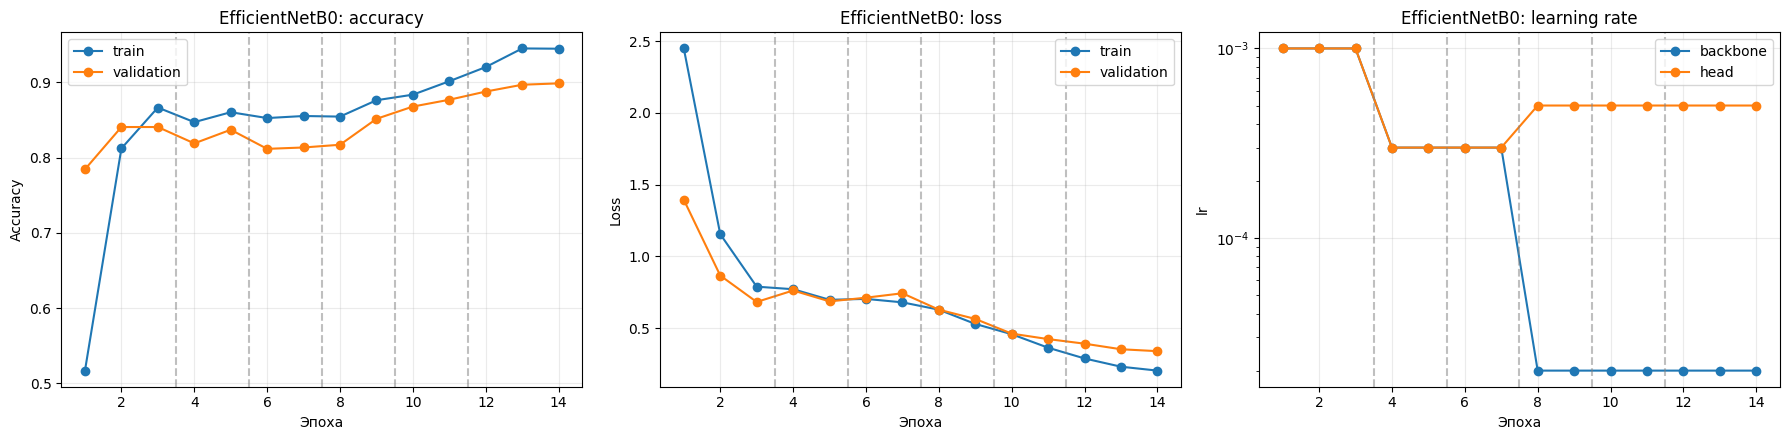


Learning rate по этапам — EfficientNetB0


,backbone_first,backbone_last,head_first,head_last
stage,,,,
Базовая,0.00100,0.00100,0.0010,0.0010
Аугментация: medium,0.00030,0.00030,0.0003,0.0003
Аугментация: strong,0.00030,0.00030,0.0003,0.0003
Разморозка: последний блок,0.00002,0.00002,0.0005,0.0005
Разморозка: вся сеть,0.00002,0.00002,0.0005,0.0005
Псевдометки,0.00002,0.00002,0.0005,0.0005


In [ ]:
def plot_history(history: pd.DataFrame, model_name: str) -> None:
    """Accuracy, loss and learning rate through all stages."""
    epochs = np.arange(1, len(history) + 1)
    stage_sizes = history.groupby("stage", sort=False).size()
    boundaries = np.cumsum(stage_sizes.values)[:-1]

    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

    axes[0].plot(epochs, history["train_accuracy"],
                 marker="o", label="train")
    axes[0].plot(epochs, history["val_accuracy"],
                 marker="o", label="validation")
    axes[0].set_title(f"{model_name}: accuracy")
    axes[0].set_ylabel("Accuracy")

    axes[1].plot(epochs, history["train_loss"],
                 marker="o", label="train")
    axes[1].plot(epochs, history["val_loss"],
                 marker="o", label="validation")
    axes[1].set_title(f"{model_name}: loss")
    axes[1].set_ylabel("Loss")

    axes[2].plot(epochs, history["lr_backbone"],
                 marker="o", label="backbone")
    axes[2].plot(epochs, history["lr_head"],
                 marker="o", label="head")
    axes[2].set_yscale("log")
    axes[2].set_title(f"{model_name}: learning rate")
    axes[2].set_ylabel("lr")

    for ax in axes:
        ax.set_xlabel("Эпоха")
        ax.legend()
        ax.grid(alpha=0.25)
        for boundary in boundaries:
            ax.axvline(
                boundary + 0.5,
                color="gray",
                linestyle="--",
                alpha=0.5,
            )

    plt.tight_layout()
    plt.show()


for model_name, result in experiments.items():
    plot_history(result["history"], model_name)

    lr_summary = result["history"].groupby("stage", sort=False).agg(
        backbone_first=("lr_backbone", "first"),
        backbone_last=("lr_backbone", "last"),
        head_first=("lr_head", "first"),
        head_last=("lr_head", "last"),
    )
    print()
    print(f"Learning rate по этапам — {model_name}")
    display(lr_summary)

Разрыв между train и validation на графиках есть: train accuracy выше, train loss продолжает падать, а validation loss на последних этапах почти не уменьшается. Это может говорить о переобучении — в train всего 2576 изображений.

Но интерпретировать разрыв стоит осторожно. Между этапами меняются аугментация, режим обучения и состав данных: на этапе псевдометок картинок становится больше. Поэтому кривые до и после границы этапа сравниваются не в одинаковых условиях. Кроме того, большее число эпох само по себе не гарантирует лучшего обобщения — на небольшом датасете модель быстрее запоминает train, чем учится общему признаку.

Таблица learning rate показывает работу scheduler: у ResNet50 на этапе псевдометок lr снизился вдвое после эпохи, где validation loss вырос. На этапах из двух эпох scheduler часто не успевает сработать — это ожидаемо, основную адаптацию здесь даёт дифференцированный lr по группам слоёв.


## 16. Выводы

1. **Baseline уже сильный.** Замороженные признаки ImageNet решают задачу неплохо: ResNet50 сразу даёт 89,86% accuracy на validation, EfficientNetB0 — 84,06%. Основные улучшения действительно лежат в адаптации backbone, а не в голове.

2. **Итеративная аугментация помогает не всегда.** На ResNet50 она добавила +1,44 п.п., на EfficientNetB0 дала −2,72 п.п. При замороженном backbone сильные искажения уводят данные из распределения ImageNet, а голове нечем подстроиться. Эффект зависит от того, насколько модель уже адаптирована к данным.

3. **Разморозка с разным lr — самый результативный этап.** ResNet50: +0,19 п.п., EfficientNetB0: +6,34 п.п. Постепенность важна: голова учится на 5e-4, последний блок — на 1e-4, ранние слои — на 1e-5–2e-5, поэтому предобученные признаки не разрушаются.

4. **Псевдолейблинг даёт умеренный эффект.** ResNet50: +1,99 п.п. при 465 псевдометках из 552 и точности 97,85%; EfficientNetB0: +2,18 п.п. при 257 метках и точности 99,22%. Пул маленький — 552 изображения, это 10–18% от train, поэтому даже почти идеальные метки не могут дать большой прирост. На большом неразмеченном пуле этап раскрылся бы сильнее.

5. **Итог на test.** ResNet50 — accuracy 90,52%, macro-F1 90,23%; EfficientNetB0 — 85,85% и 85,61%. Более сильная архитектура выигрывает, когда данных и эпох немного.

6. **Методы не универсальны.** Один и тот же набор приёмов почти монотонно улучшил ResNet50, а у EfficientNetB0 аугментация сначала ухудшила результат. Порог псевдометок, интенсивность аугментации и lr для слоёв нужно подбирать под модель и объём данных.

**Ограничения работы.** Эксперимент запускался с одним seed и небольшим числом эпох; train — 2576 изображений, поэтому разброс в 1–2 п.п. между запусками возможен. Не использовались TTA, усреднение моделей и подбор гиперпараметров на отдельной выборке.